In [1]:
# Used to Hide Codes
from IPython.display import HTML

HTML("""
<style>
#toggle-code-button {
    background-color: indigo;
    color: white;
    padding: 6px 12px;
    margin-bottom: 10px;
    border: none;
    cursor: pointer;
    font-size: 14px;
}
#toggle-code-button:hover {
    background-color: indigo;
}
</style>

<button id="toggle-code-button">Hide Code</button>

<script>
var codeVisible = true;

document.getElementById('toggle-code-button').onclick = function() {
    var code_cells = document.querySelectorAll('.input');

    codeVisible = !codeVisible;

    code_cells.forEach(function(cell) {
        cell.style.display = codeVisible ? '' : 'none';
    });

    this.innerText = codeVisible ? 'Hide Code' : 'Show Code';
};
</script>
""")

In [2]:
import os
import re
import time
from typing import List

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import praw
from pymongo import MongoClient, errors

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

import matplotlib.pyplot as plt
from IPython.display import clear_output
from textblob import TextBlob
from IPython.display import clear_output
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import ipywidgets as widgets
from ipywidgets import interact
import ipywidgets as widgets
from ipywidgets import interact
from prawcore.exceptions import TooManyRequests


In [3]:
# Configuration

# Load private settings from the .env file (never upload .env to GitHub)
from dotenv import load_dotenv
load_dotenv()

REDDIT_CLIENT_ID = os.environ.get("REDDIT_CLIENT_ID")
REDDIT_CLIENT_SECRET = os.environ.get("REDDIT_CLIENT_SECRET")
REDDIT_USER_AGENT = os.environ.get("REDDIT_USER_AGENT", "CyberStreamCoursework/1.0")

# Project paths
PROJECT_DIR = os.environ.get("CYBER_PROJECT_DIR", os.getcwd())
LIVE = os.path.join(PROJECT_DIR, "live_stream")
os.makedirs(LIVE, exist_ok=True)

# MongoDB configuration
MONGO_URI = os.environ.get("MONGO_URI", "mongodb://localhost:27017/")
MONGO_DB_NAME = os.environ.get("MONGO_DB_NAME", "cyber_stream")
MONGO_COLLECTION_NAME = os.environ.get("MONGO_COLLECTION_NAME", "reddit_live")

# Cybersecurity-related subreddits
SUBREDDITS: List[str] = [
    "cybersecurity",
    "netsec",
    "privacy",
    "infosec",
    "hacking",
    "malware",
    "blueteamsec",
    "netsecstudents",
    "pwned",
    "dataisugly",
    "infosecNews",
    "CyberNews",
    "AskNetsec",
    "ReverseEngineering"
]

# Sentiment thresholds
TB_POS, TB_NEG = 0.1, -0.1
VADER_POS, VADER_NEG = 0.05, -0.05


In [4]:
# NLTK + SENTIMENT SETUP

try:
    nltk.data.find("tokenizers/punkt")
except LookupError:
    nltk.download("punkt")

try:
    nltk.data.find("corpora/stopwords")
except LookupError:
    nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
vader = SentimentIntensityAnalyzer()

URL_RE = re.compile(r"http\S+|www\S+|https\S+", flags=re.MULTILINE)


In [5]:
# CLEANING of TEXT 

def light_clean(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = URL_RE.sub("", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

def heavy_clean(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = URL_RE.sub("", text)
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w.isalpha() and w not in stop_words]
    return " ".join(tokens).strip()
# Sentiment Helpers and Reddit Client

def get_tb_score(text: str) -> float:
    try:
        return float(TextBlob(text).sentiment.polarity)
    except Exception:
        return 0.0


def get_vader_score(text: str) -> float:
    try:
        return float(vader.polarity_scores(text)["compound"])
    except Exception:
        return 0.0


def get_tb_label(score: float) -> str:
    if score > TB_POS:
        return "positive"
    if score < TB_NEG:
        return "negative"
    return "neutral"


def get_vader_label(score: float) -> str:
    if score > VADER_POS:
        return "positive"
    if score < VADER_NEG:
        return "negative"
    return "neutral"


In [6]:
# Reddit Client

def get_reddit_client() -> praw.Reddit:
    
    if not REDDIT_CLIENT_ID or not REDDIT_CLIENT_SECRET:
        raise RuntimeError(
            "Missing Reddit credentials. Set REDDIT_CLIENT_ID and "
            "REDDIT_CLIENT_SECRET as environment variables."
        )

    reddit = praw.Reddit(
        client_id=REDDIT_CLIENT_ID,
        client_secret=REDDIT_CLIENT_SECRET,
        user_agent=REDDIT_USER_AGENT,
    )
    return reddit


# 7. AUTO TIME BUCKET PICKER (for interactive mode)

def pick_time_bucket(df_all: pd.DataFrame, target_bins: int = 40) -> str:
   
    if df_all is None or df_all.empty or "created_utc" not in df_all.columns:
        return "25min"

    df_tmp = df_all.copy()
    df_tmp["timestamp"] = pd.to_datetime(
        df_tmp["created_utc"], unit="s", errors="coerce"
    )
    df_tmp = df_tmp.dropna(subset=["timestamp"])
    if df_tmp.empty:
        return "25min"

    t_min = df_tmp["timestamp"].min()
    t_max = df_tmp["timestamp"].max()
    span_minutes = (t_max - t_min).total_seconds() / 60.0

    if span_minutes <= 0:
        return "25min"

    ideal_minutes_per_bin = span_minutes / max(target_bins, 1)

    candidates = [1, 5, 15, 25, 30, 60]
    chosen = candidates[-1]
    for c in candidates:
        if ideal_minutes_per_bin <= c:
            chosen = c
            break

    return f"{chosen}min" if chosen < 60 else "60min"

In [7]:
# 8. LIVE SENTENCES PANEL

def show_live_examples(
    df_all: pd.DataFrame,
    recent_window: int = 300,
    n_examples: int = 6,
) -> None:
    
    if df_all is None or df_all.empty:
        print("\n[Examples] No data yet.")
        return

    df_recent = df_all.tail(recent_window).copy()
    if df_recent.empty:
        print("\n[Examples] No recent data in window.")
        return

    n = min(n_examples, len(df_recent))
    sample = df_recent.sample(n=n)

    print("\n" + "=" * 80)
    print(f" LIVE EXAMPLE POSTS (from last {len(df_recent)} posts)")
    print("=" * 80)

    for _, row in sample.iterrows():
        text = row.get("content", row.get("clean_text", ""))
        text_short = (text[:400] + "…") if len(text) > 400 else text

        print("-" * 80)
        print(f"Post ID     : {row.get('id', 'N/A')}")
        print(f"Subreddit   : {row.get('subreddit', 'N/A')}")
        print(f"Created_utc : {row.get('created_utc', 'N/A')}")
        print()
        print("TEXT:")
        print(text_short)
        print()
        print(f"VADER   → Score: {row.get('vader_score', 0.0):+.3f} | Label: {row.get('vader_label', 'N/A')}")
        print(f"TextBlob→ Score: {row.get('tb_score', 0.0):+.3f} | Label: {row.get('tb_label', 'N/A')}")
        print("-" * 80)

    print()  # extra newline

In [8]:
# 9. BACKFILL RECENT POSTS


def backfill_recent_posts(
    reddit: praw.Reddit,
    live_col,
    limit_per_sub: int,
    all_docs: List[dict],
):
    print(f"\nBackfilling recent posts (limit_per_sub={limit_per_sub})...")
    total_inserted = 0
    total_collected = 0

    for s in SUBREDDITS:
        print(f"  Fetching recent from r/{s} ...")
        try:
            subreddit = reddit.subreddit(s)
            for post in subreddit.new(limit=limit_per_sub):

                raw_title = post.title or ""
                raw_text = post.selftext or ""
                content = (raw_title + " " + raw_text).strip()

                if not content or len(content.split()) < 2:
                    continue

                content_lc = light_clean(content)
                clean = heavy_clean(content)

                tb = get_tb_score(content_lc)
                vd = get_vader_score(content_lc)

                now = time.time()
                doc = {
                    "id": post.id,
                    "subreddit": str(post.subreddit).lower(),
                    "raw_title": raw_title,
                    "raw_text": raw_text,
                    "content": content,
                    "content_lc": content_lc,
                    "clean_text": clean,
                    "created_utc": float(post.created_utc),
                    "tb_score": tb,
                    "tb_label": get_tb_label(tb),
                    "vader_score": vd,
                    "vader_label": get_vader_label(vd),
                    "ingested_at": now,
                }

                try:
                    live_col.insert_one(doc)
                    total_inserted += 1
                except errors.DuplicateKeyError:
                    pass
                except Exception as e:
                    print(f"    Error inserting doc from r/{s}: {e}")

                all_docs.append(doc)
                total_collected += 1

        except Exception as e:
            print(f"  Error while fetching r/{s}: {e}")

    print(f"Backfill complete. Inserted ~{total_inserted} new docs.")
    print(f"Backfill collected {total_collected} docs in memory for the dashboard.")


In [9]:
# 10. DASHBOARD (2×2)

def update_live_dashboard(
    df_all: pd.DataFrame,
    recent_window: int = 700,
    time_bucket: str = "15min",
) -> None:
    
    if df_all is None or df_all.empty:
        clear_output(wait=True)
        print("No live data yet...")
        return

    df_recent = df_all.tail(recent_window)
    if df_recent.empty:
        clear_output(wait=True)
        print("No recent data available for dashboard update.")
        return

    if recent_window and len(df_all) > recent_window:
        df_all = df_all.tail(recent_window).copy()

    df_trend = df_all.sort_values("created_utc").copy()
    df_trend["timestamp"] = pd.to_datetime(
        df_trend["created_utc"], unit="s", errors="coerce"
    )
    df_trend["time_bucket"] = df_trend["timestamp"].dt.floor(time_bucket)

    sentiment_order = ["positive", "neutral", "negative"]

    # Subreddit × VADER sentiment
    heat = (
        df_all
        .groupby(["subreddit", "vader_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=sentiment_order, fill_value=0)
    )
    subreddits = heat.index.tolist()

    # VADER trend
    vader_trend_counts = (
        df_trend
        .groupby(["time_bucket", "vader_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=sentiment_order, fill_value=0)
    )

    # TextBlob trend
    tb_trend_counts = (
        df_trend
        .groupby(["time_bucket", "tb_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=sentiment_order, fill_value=0)
    )

    max_buckets = 20
    vader_plot = vader_trend_counts.tail(max_buckets)
    tb_plot = tb_trend_counts.tail(max_buckets)

    tb_counts = (
        df_recent["tb_label"]
        .value_counts()
        .reindex(sentiment_order, fill_value=0)
        .astype(int)
    )
    vd_counts = (
        df_recent["vader_label"]
        .value_counts()
        .reindex(sentiment_order, fill_value=0)
        .astype(int)
    )

    vader_colors = {
        "positive": "steelblue",
        "neutral": "grey",
        "negative": "red",
    }
    tb_colors = {
        "positive": "steelblue",
        "neutral": "grey",
        "negative": "purple",
    }

    plt.rcParams.update({
        "font.size": 12,
        "axes.titlesize": 16,
        "axes.labelsize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 12,
    })

    clear_output(wait=True)

    fig, axes = plt.subplots(2, 2, figsize=(25, 14))
    ax_comp, ax_sub, ax_vader, ax_tb = axes.flatten()

    # --- 1) TextBlob vs VADER Summary (TOP-LEFT) ---
    x_sent = np.arange(len(sentiment_order))
    bar_width = 0.35

    bars_tb = ax_comp.bar(
        x_sent - bar_width / 2,
        tb_counts.values,
        width=bar_width,
        label="TextBlob",
        color="deepskyblue",
        edgecolor="black",
        linewidth=0.8,
    )
    bars_vd = ax_comp.bar(
        x_sent + bar_width / 2,
        vd_counts.values,
        width=bar_width,
        label="VADER",
        color="darkorange",
        edgecolor="black",
        linewidth=0.8,
    )

    total_sentiment_posts = int(tb_counts.sum()) if tb_counts.sum() > 0 else 1
    for bar in list(bars_tb) + list(bars_vd):
        val = int(bar.get_height())
        if val > 0:
            pct = (val / total_sentiment_posts) * 100
            ax_comp.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() / 2,
                f"{val}\n{pct:.1f}%",
                va="center",
                ha="center",
                fontsize=13,
                color="white",
                fontweight="bold",
            )

    ax_comp.set_xticks(x_sent)
    ax_comp.set_xticklabels([s.capitalize() for s in sentiment_order])
    ax_comp.set_title(f"Recent Sentiment Counts (last ~{len(df_recent)} posts)")
    ax_comp.set_ylabel("Number of posts")
    ax_comp.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax_comp.spines[spine].set_visible(False)
    ax_comp.legend(frameon=False, loc="upper right")

    #  2) VADER Sentiment by Subreddit (TOP-RIGHT)
    if len(subreddits) > 0:
        x = np.arange(len(subreddits))
        for sentiment in sentiment_order:
            y = heat[sentiment].values
            ax_sub.plot(
                x,
                y,
                marker="o",
                linewidth=1.8,
                markersize=9,
                label=sentiment.capitalize(),
                color=vader_colors[sentiment],
            )
            for xi, yi in zip(x, y):
                if yi > 0:
                    ax_sub.text(
                        xi,
                        yi + 1,
                        str(int(yi)),
                        ha="center",
                        va="bottom",
                        fontsize=11,
                        fontweight="bold",
                        color=vader_colors[sentiment],
                    )

        ax_sub.set_xticks(x)
        ax_sub.set_xticklabels(subreddits, rotation=45, ha="right")
        ax_sub.set_title("VADER Sentiment by Subreddit")
        ax_sub.set_xlabel("Subreddit")
        ax_sub.set_ylabel("Number of posts")
        ax_sub.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax_sub.spines[spine].set_visible(False)
        ax_sub.legend(title="Sentiment", frameon=False, loc="upper left")
    else:
        ax_sub.text(0.5, 0.5, "No subreddit data yet", ha="center", va="center",
                    transform=ax_sub.transAxes)
        ax_sub.set_axis_off()

    #  3) VADER Trend (BOTTOM-LEFT)
    if not vader_plot.empty:
        times = vader_plot.index

        for sentiment in sentiment_order:
            y = vader_plot[sentiment].values
            ax_vader.plot(
                times,
                y,
                marker="o",
                linewidth=2.0,
                markersize=6,
                label=sentiment.capitalize(),
                color=vader_colors[sentiment],
            )

            if len(times) > 0:
                ax_vader.text(
                    times[-1],
                    y[-1] + 0.3,
                    str(int(y[-1])),
                    ha="center",
                    va="bottom",
                    fontsize=10,
                    color=vader_colors[sentiment],
                    fontweight="bold",
                )

        n_t = len(times)
        tick_step = max(1, n_t // 8)
        ax_vader.set_xticks(times[::tick_step])
        ax_vader.set_xticklabels(
            [t.strftime("%m-%d %H:%M") for t in times[::tick_step]],
            rotation=45,
            ha="right",
        )

        ax_vader.set_title("VADER Sentiment Trend")
        ax_vader.set_xlabel("Time")
        ax_vader.set_ylabel("Number of posts")
        ax_vader.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax_vader.spines[spine].set_visible(False)
        ax_vader.legend(title="Sentiment", frameon=False, loc="upper left")
    else:
        ax_vader.text(0.5, 0.5, "No VADER time-series data yet",
                      ha="center", va="center", transform=ax_vader.transAxes)
        ax_vader.set_axis_off()

    #  4) TextBlob Trend (BOTTOM-RIGHT) 
    if not tb_plot.empty:
        times_tb = tb_plot.index

        for sentiment in sentiment_order:
            y = tb_plot[sentiment].values
            ax_tb.plot(
                times_tb,
                y,
                marker="o",
                linewidth=2.0,
                markersize=6,
                label=sentiment.capitalize(),
                color=tb_colors[sentiment],
            )

            if len(times_tb) > 0:
                ax_tb.text(
                    times_tb[-1],
                    y[-1] + 0.3,
                    str(int(y[-1])),
                    ha="center",
                    va="bottom",
                    fontsize=10,
                    color=tb_colors[sentiment],
                    fontweight="bold",
                )

        n_t_tb = len(times_tb)
        tick_step = max(1, n_t_tb // 8)
        ax_tb.set_xticks(times_tb[::tick_step])
        ax_tb.set_xticklabels(
            [t.strftime("%m-%d %H:%M") for t in times_tb[::tick_step]],
            rotation=45,
            ha="right",
        )

        ax_tb.set_title("TextBlob Sentiment Trend")
        ax_tb.set_xlabel("Time")
        ax_tb.set_ylabel("Number of posts")
        ax_tb.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax_tb.spines[spine].set_visible(False)
        ax_tb.legend(title="Sentiment", frameon=False, loc="upper left")
    else:
        ax_tb.text(0.5, 0.5, "No TextBlob time-series data yet",
                   ha="center", va="center", transform=ax_tb.transAxes)
        ax_tb.set_axis_off()

    plt.tight_layout()
    plt.show()

    print(f"Total streamed posts in memory: {len(df_all)}")
    print(f"Time bucket size: {time_bucket}")
    print(f"Latest post time: {df_trend['timestamp'].max()}")
    print(f"Window size used for dashboard: last {len(df_recent)} posts\n")

    show_live_examples(df_all, recent_window=recent_window, n_examples=6)


In [10]:
# 11. LIVE STREAMING LOOP


def stream_reddit_live(
    live_plot: bool = True,
    max_docs_in_memory: int = 10000,
    save_csv_every: int = 1000,
    backfill_limit_per_sub: int = 500,
) -> List[dict]:

    reddit = get_reddit_client()
    mongo_client = MongoClient(MONGO_URI)
    mongo_db = mongo_client[MONGO_DB_NAME]
    live_col = mongo_db[MONGO_COLLECTION_NAME]

    try:
        live_col.create_index("id", unique=True)
        print("Unique index on 'id' ensured.")
    except errors.PyMongoError as e:
        print(f"Warning: could not create unique index on 'id': {e}")

    all_docs: List[dict] = []

    # Backfill
    backfill_recent_posts(
        reddit=reddit,
        live_col=live_col,
        limit_per_sub=backfill_limit_per_sub,
        all_docs=all_docs,
    )

    # Show dashboard once after backfill
    if live_plot and all_docs:
        df_all = pd.DataFrame(all_docs)
        update_live_dashboard(df_all, recent_window=2000, time_bucket="15min")

    # Start live stream
    sub_str = "+".join(SUBREDDITS)
    subreddit = reddit.subreddit(sub_str)

    print(f"\nStreaming LIVE from: {sub_str}")
    print("Using PRAW stream.submissions(skip_existing=True)")
    print(f"MongoDB: {MONGO_URI} → {MONGO_DB_NAME}.{MONGO_COLLECTION_NAME}")
    print(f"Live CSV directory: {LIVE}")

    processed_count = 0

    try:
        for post in subreddit.stream.submissions(skip_existing=True):
            time.sleep(1)  # avoid rate limits

            s = str(post.subreddit).lower()
            if s not in [x.lower() for x in SUBREDDITS]:
                continue

            raw_title = post.title or ""
            raw_text = post.selftext or ""
            content = (raw_title + " " + raw_text).strip()
            if not content or len(content.split()) < 2:
                continue

            content_lc = light_clean(content)
            clean = heavy_clean(content)

            tb = get_tb_score(content_lc)
            vd = get_vader_score(content_lc)

            now = time.time()
            doc = {
                "id": post.id,
                "subreddit": s,
                "raw_title": raw_title,
                "raw_text": raw_text,
                "content": content,
                "content_lc": content_lc,
                "clean_text": clean,
                "created_utc": float(post.created_utc),
                "tb_score": tb,
                "tb_label": get_tb_label(tb),
                "vader_score": vd,
                "vader_label": get_vader_label(vd),
                "ingested_at": now,
            }

            all_docs.append(doc)
            if len(all_docs) > max_docs_in_memory:
                all_docs = all_docs[-max_docs_in_memory:]

            try:
                live_col.insert_one(doc)
                print(f"[LIVE] [{s}] {post.id} | {raw_title[:80]!r}")
            except errors.DuplicateKeyError:
                print(f"[DUPLICATE] [{s}] {post.id} already in MongoDB")
            except Exception as e:
                print(f"Error inserting into MongoDB: {e}")

            processed_count += 1

            # Save CSV snapshots
            if save_csv_every and processed_count % save_csv_every == 0:
                df_cycle = pd.DataFrame(all_docs[-save_csv_every:])
                ts = int(time.time())
                csv_path = os.path.join(LIVE, f"reddit_live_{ts}.csv")
                try:
                    df_cycle.to_csv(csv_path, index=False, encoding="utf-8")
                    print(f"Saved last {save_csv_every} posts to {csv_path}.")
                except Exception as e:
                    print(f"Error saving CSV: {e}")

            # Update dashboard with fixed 15-minute bucket
            if live_plot and all_docs:
                df_all = pd.DataFrame(all_docs)
                update_live_dashboard(df_all, recent_window=2000, time_bucket="15min")

    except TooManyRequests:
        print("\nHit Reddit API rate limit (HTTP 429)")
        print("Stopping the stream but keeping collected posts.")

    except KeyboardInterrupt:
        print("\nKeyboardInterrupt received. Stopping stream cleanly.")

    finally:
        mongo_client.close()
        print("MongoDB connection closed.")
        return all_docs


In [11]:
# 12. INTERACTIVE DASHBOARD (OFFLINE MODE)

def interactive_dashboard(df_all: pd.DataFrame, recent_window: int = 700):
    def _update(bucket):
        if bucket == "auto":
            bucket_eff = pick_time_bucket(df_all)
        else:
            bucket_eff = bucket

        update_live_dashboard(
            df_all,
            recent_window=recent_window,
            time_bucket=bucket_eff,
        )

    interact(
        _update,
        bucket=widgets.Dropdown(
            options=[
                ("Auto (based on data)", "auto"),
                ("1 min", "1min"),
                ("5 min", "5min"),
                ("15 min", "15min"),
                ("25 min", "25min"),
                ("30 min", "30min"),
                ("60 min", "60min"),
            ],
            value="auto",
            description="Time bucket:",
        ),
    )

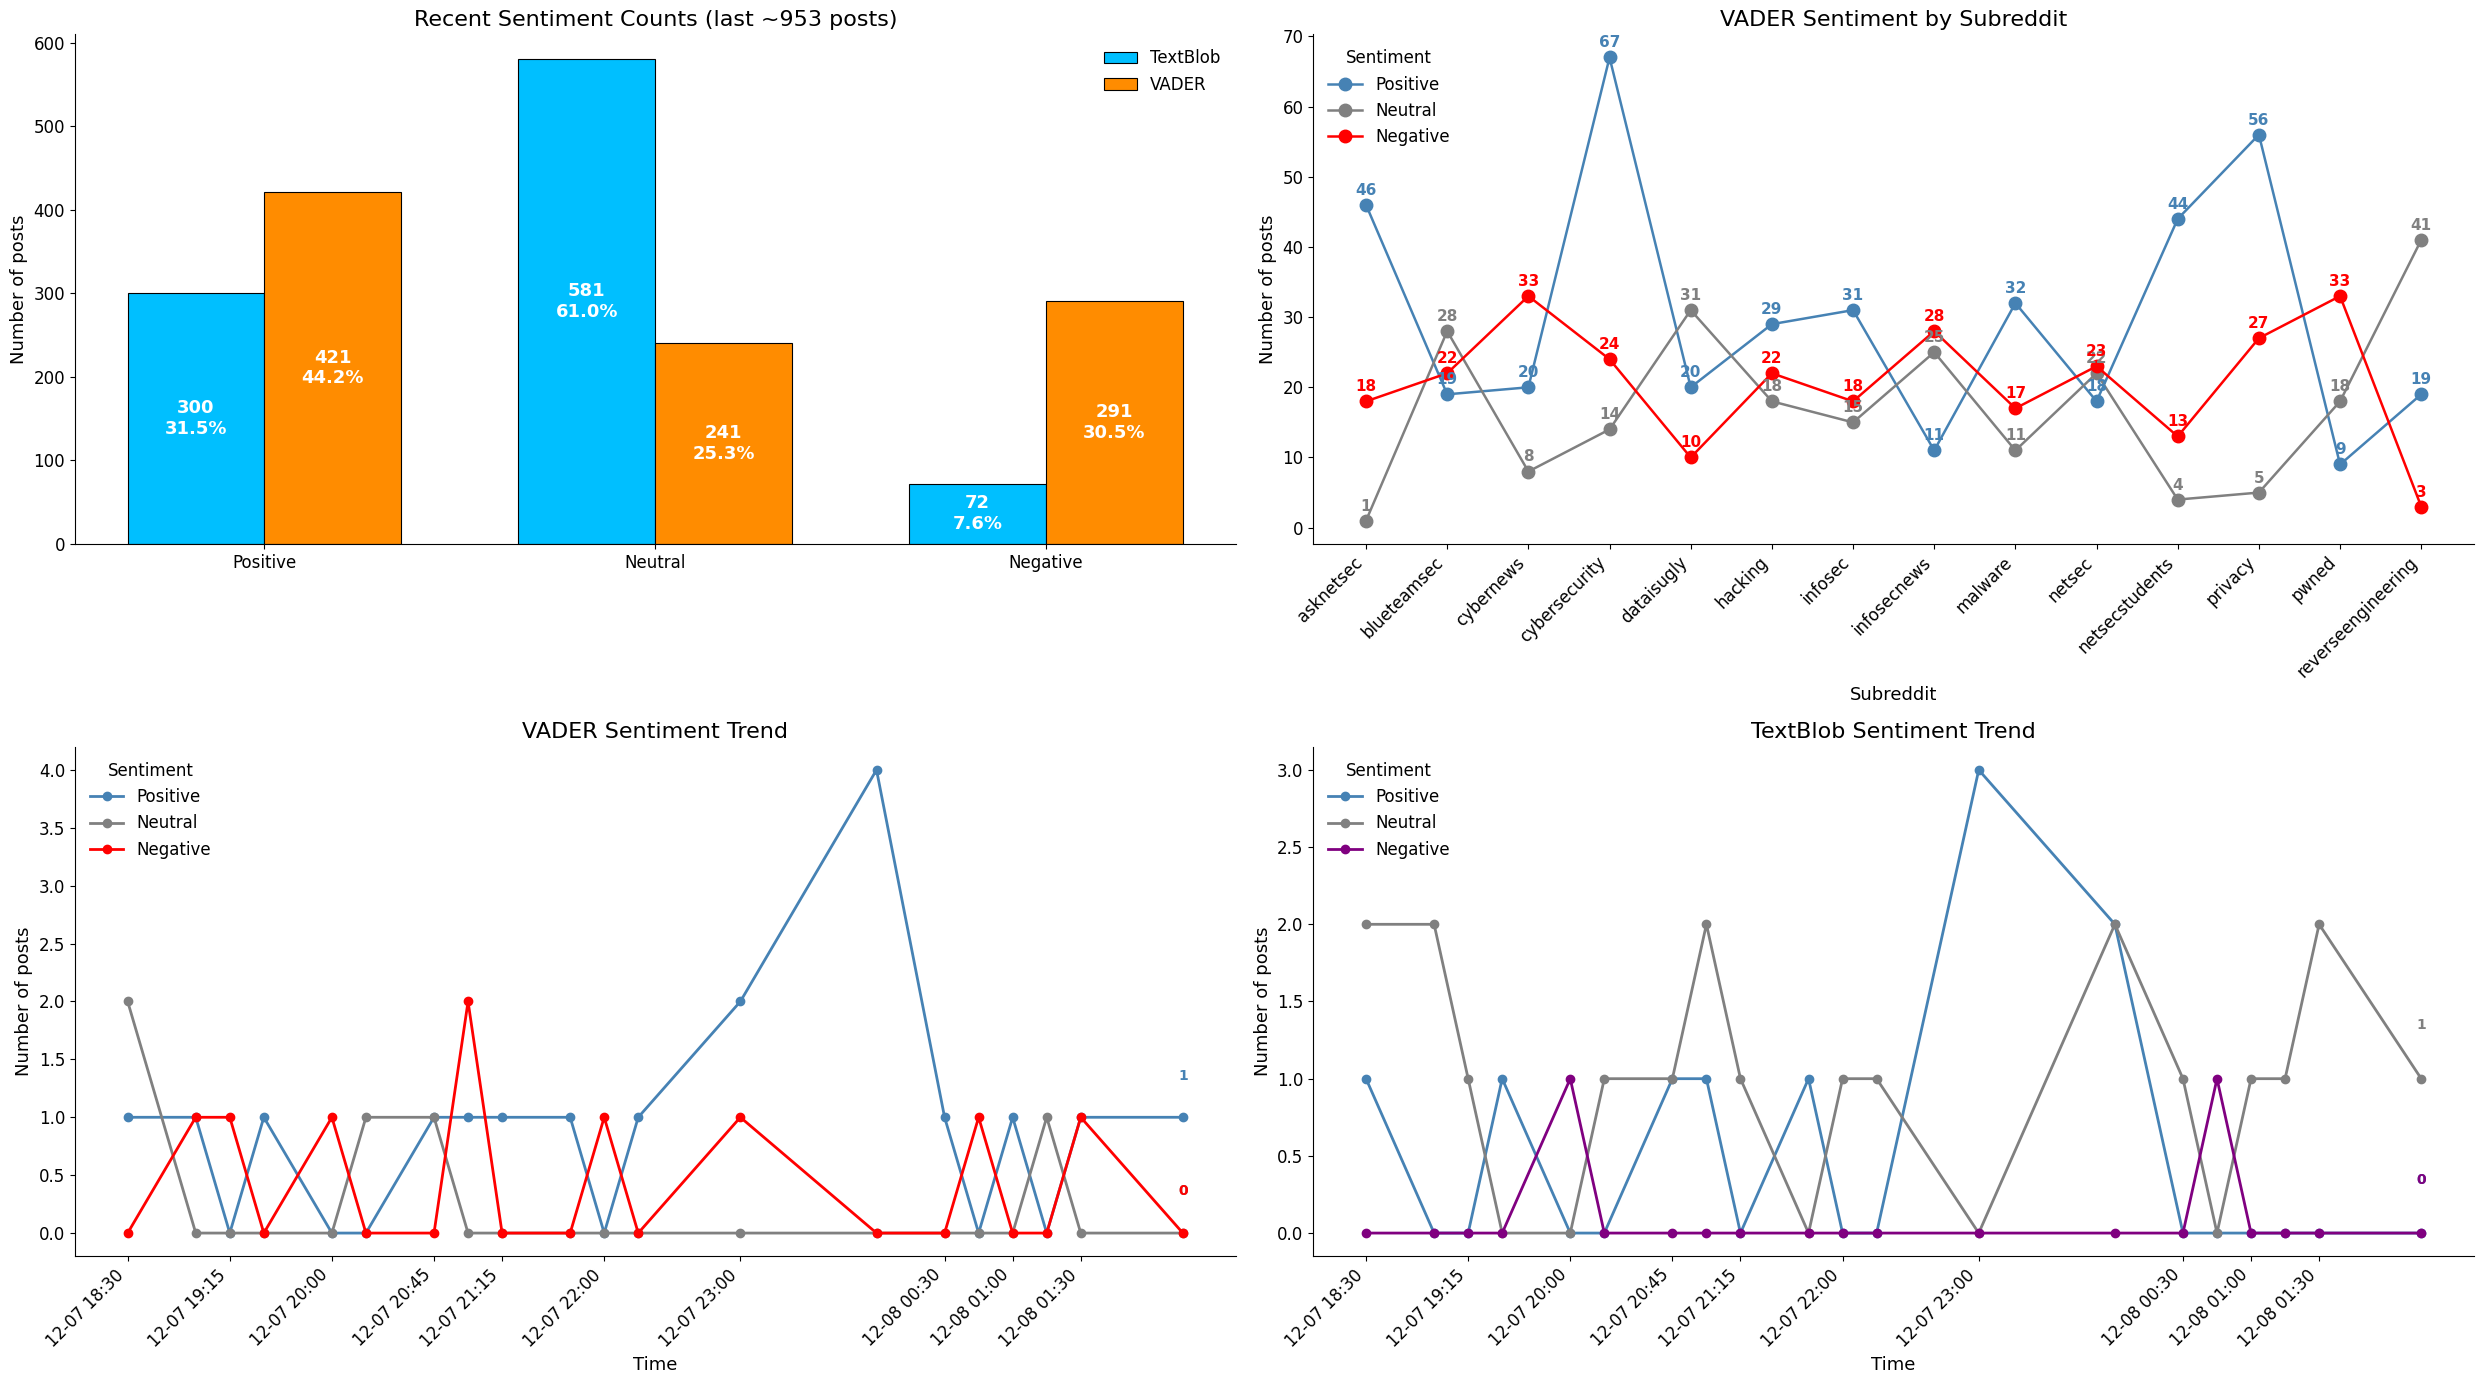

Total streamed posts in memory: 953
Time bucket size: 15min
Latest post time: 2025-12-08 02:29:15
Window size used for dashboard: last 953 posts


 LIVE EXAMPLE POSTS (from last 953 posts)
--------------------------------------------------------------------------------
Post ID     : zrvxti
Subreddit   : pwned
Created_utc : 1671645852.0

TEXT:
Okta's source code stolen after GitHub repositories compromised

VADER   → Score: -0.494 | Label: negative
TextBlob→ Score: +0.000 | Label: neutral
--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
Post ID     : 1pbbq69
Subreddit   : netsec
Created_utc : 1764592818.0

TEXT:
Bind Link – EDR Tampering

VADER   → Score: +0.000 | Label: neutral
TextBlob→ Score: +0.000 | Label: neutral
--------------------------------------------------------------------------------
------------------------------------------------------------------------------

In [ ]:
# Entry Point

# LIVE MODE: dashboard updates automatically as new posts arrive
stream_reddit_live(
    live_plot=True,
    max_docs_in_memory=2000,
    save_csv_every=150,
    backfill_limit_per_sub=60,
)

# # If you later want to explore the collected data offline:
# df_all = pd.DataFrame(all_docs)
# interactive_dashboard(df_all, recent_window=2000)
